In [193]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [225]:
import pandas as pd
import numpy as np
import json
import random
import ipywidgets as widgets
import matplotlib.pyplot as plt

from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from IPython.display import display
from sklearn.metrics import silhouette_score
from sklearn.cluster import KMeans
from src.graficos import plot_silhouette_inercia, plot_vecinos_knn
from src.splitting import split_estratificado_autor

# Cargo los datasets

In [195]:
#LEO TEST
chunks_test = pd.read_json("set_test_1.json", lines=True, chunksize=100_000)
chunk_list_test = []
for chunk in chunks_test:
    chunk_list_test.append(chunk)
df_test = pd.concat(chunk_list_test, ignore_index=True)

#LEO VAL
chunks_val = pd.read_json("set_val_1.json", lines=True, chunksize=100_000)
chunk_list_val = []
for chunk in chunks_val:
    chunk_list_val.append(chunk)
df_val = pd.concat(chunk_list_val, ignore_index=True)

#LEO TRAIN
chunks_train = pd.read_json("set_train_1.json", lines=True, chunksize=100_000)
chunk_list_train = []
for chunk in chunks_train:
    chunk_list_train.append(chunk)
df_train = pd.concat(chunk_list_train, ignore_index=True)

#LEO AUTORES
chunks_autores = pd.read_json("goodreads_book_authors.json", lines=True, chunksize=100_000)
chunk_list_autores = []
for chunk in chunks_autores:
    chunk_list_autores.append(chunk)
df_autores = pd.concat(chunk_list_autores, ignore_index=True)

# Preparacion de los datos

Utilizo el dataset de autores para asociar los IDs que ya tenemos, con sus nombres correspondientes:

In [196]:
descripcion_emb_train = np.load("descripcion_emb_train.npy")
descripcion_emb_val = np.load("descripcion_emb_val.npy")
descripcion_emb_test = np.load("descripcion_emb_test.npy")

In [197]:
#Creo las columnas para el dataset:
descripcion_colum = [f"description_emb_{num}" for num in range(50)]

descripcion_emb_train_df = pd.DataFrame(descripcion_emb_train, columns = descripcion_colum, index = df_train.index)
df_train = df_train.join(descripcion_emb_train_df)

descripcion_emb_val_df = pd.DataFrame(descripcion_emb_val, columns = descripcion_colum, index = df_val.index)
df_val = df_val.join(descripcion_emb_val_df)

descripcion_emb_test_df = pd.DataFrame(descripcion_emb_test, columns = descripcion_colum, index = df_test.index)
df_test = df_test.join(descripcion_emb_test_df)

In [198]:
#UNIFICO TRAIN, VAL, TEST EN UN UNICO DF 
df = pd.concat([df_train, df_val, df_test], ignore_index=True)

In [199]:
#Al hacer merge, usamos "how = left" para que quedarnos con todas las muestras de df_train (aunque no lo encuentre coincidencia).
#Si no encuentra el ID de df en df_autores, simplemente completa con NaN
df = df.merge(df_autores[["author_id", "name"]], left_on = "author_id_principal", right_on = "author_id", how = "left")
#Despues del merge, tenemos entonces entre las columnas a : "author_id_principal", "author_id" y "author_name"
#Pero como son el mismo ID, elimino una de las dos:
df = df.drop(columns = "author_id")
#Renombro la columna:
df = df.rename(columns = {"name": "author_name"})
df["titulo_autor"] = (df["title"] + " — " + df["author_name"]) #Para la interfaz

Es mas facil eliminar las features con las que no queremos entrenar, que quedarnos con las que si, son muchas mas. 

In [200]:
df_recomendador = df[["titulo_autor", "title", "author_name"]]
df = df.drop(columns = ["title_key", "publisher", "title_text", "author_name", "titulo_autor", "language_code", "ratings_count", "authors", "format_group", "genres", "description", "title"])

In [201]:
X = df.to_numpy()

#estandarizo los datos
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Implementacion de los modelos

### 1. KNN - K nearest neighboors

In [202]:
modelo = NearestNeighbors(n_neighbors = 20, metric = "cosine")
modelo.fit(X_scaled)

,n_neighbors,20
,radius,1.0
,algorithm,'auto'
,leaf_size,30
,metric,'cosine'
,p,2
,metric_params,None
,n_jobs,None


### 2. KMeans

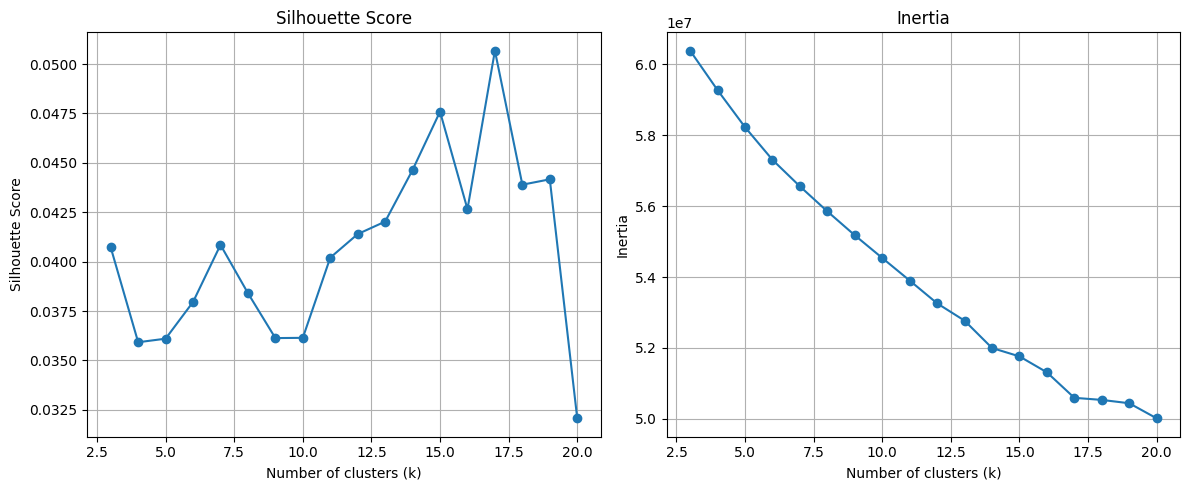

In [224]:
#disclaimer: tarda aprox 12 mins en correr

silhouettes = []
inertias = []
ks = [k for k in range(3, 21)]

#como calcular silhouette es muy pesado, predigo sobre un sample aleatorio con menos muestras
np.random.seed(42)
idx = np.random.choice(len(X_scaled), size=10000, replace=False)
X_sample = X_scaled[idx]

for k in ks:
    kmeans = KMeans(n_clusters = k, random_state = 42, n_init = 10) #n_init: cant de veces q se vuelve a correr el algoritmo con diferentes centroides, ayuda a obtener mejores resultados, deja de depender tanto del centroide inicial elegido
    kmeans.fit(X_scaled)

    #para inertia
    inertias.append(kmeans.inertia_)

    #para silhouette
    clusters = kmeans.predict(X_sample)
    silhouettes.append(silhouette_score(X_sample, clusters))

plot_silhouette_inercia(ks, silhouettes, inertias)

In [206]:
k = 18
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X)
df["cluster"] = clusters #guardo en el df el cluster al que pertenece cada libro

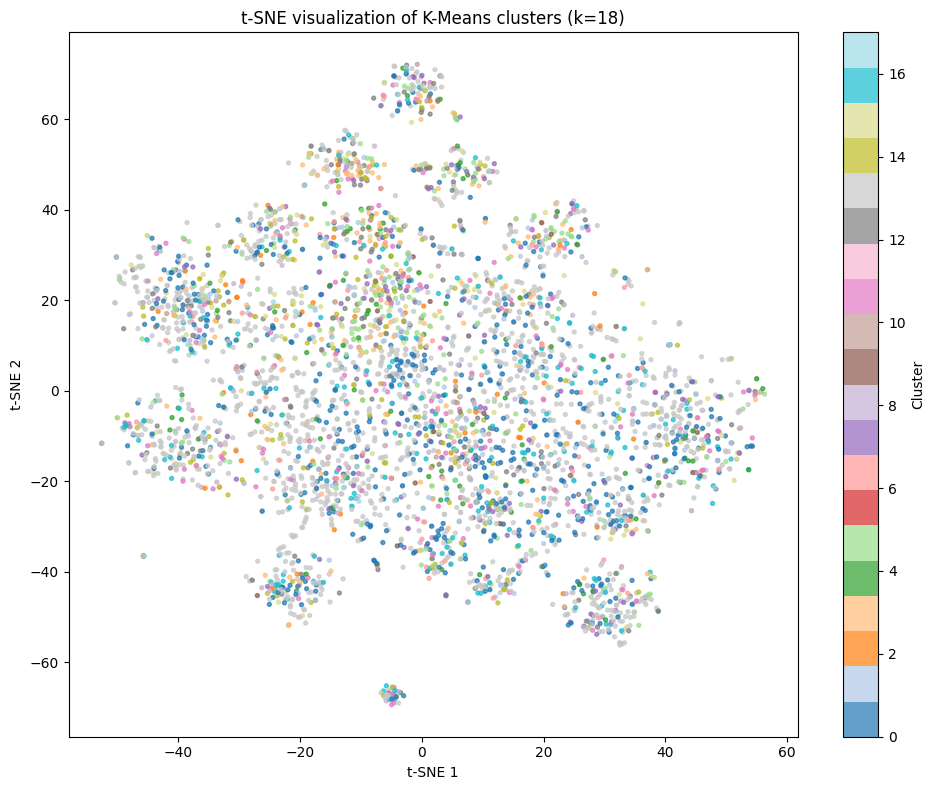

In [207]:
idx = np.random.choice(len(X_scaled), size=4000, replace=False)
X_sample = X_scaled[idx]
clusters_sample = clusters[idx]

tsne = TSNE(n_components=2, perplexity=30, random_state=42, init="pca")
X_tsne = tsne.fit_transform(X_sample)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=clusters_sample, cmap="tab20", s=8, alpha=0.7)
plt.colorbar(scatter, label="Cluster")
plt.title(f"t-SNE visualization of K-Means clusters (k={k})")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.tight_layout()
plt.show()

Como una segunda tecnica de recomendador, habiamos pensado en primer lugar hacer clustering, y luego elegir libros de ese grupo. Debido a la cantidad de muestras que tenemos, elegimos implementar KMeans. Sin embargo, debido a la cantidad de dimensiones que presenta nuestro dataset, no se lograron armar buenos clusters. Decidimos descartar este metodo de recomendacion y quedarnos con KNN. 

# Desarrollando recomendador

Una vez ya entrenado el modelo, vuelvo a unificar df_recomendador (con las features no numericas necesarias para identificar al libro) y df (con las features necesarias para entrenar)

In [208]:
df = pd.concat([df_recomendador, df], axis=1)

Defino dos funciones segun la informacion del libro que tenga: <br>
Si se tiene el indice del dataset en el que se encuentra el libro, usar recomendar_por_idx (usado en un ejemplo elegido a mano, o con un indice aleatorio). <br>
En cambio, si se tiene el titulo y autor escritos de manera exacta como en el dataset, usar recomendar_por_libro (usado en la interfaz grafica). <br>

In [209]:
#Para evitar tener que recorrer el dataset de libros cada vez que quiero buscar un libro, 
#me creo un diccionario que asocia "titulo_autor" con su indice:
titulo_a_indice = dict(zip(df["titulo_autor"], df.index)) #Reduce el tiempo de busqueda, lo que nos sirve con el dataset grande

def recomendar_por_idx(modelo, X, indice_libro, n_recomendaciones = 10):
    distancias, indices = modelo.kneighbors(X[indice_libro].reshape(1, -1), n_neighbors = n_recomendaciones + 1)
    return indices[0][1:], distancias[0][1:]

def recomendar_por_libro(modelo, libros_df, X, titulo_autor, titulo_a_indice = titulo_a_indice, cant_recomendaciones = 5):
    #Observaciones: la interfaz ya obliga al usuario a elegir un unico libro (al especificar tambien el autor),
    #entonces ya no hace chequear el caso en el que len(resultados) > 1

    #Ahora hay que ver que hacemos con cada posible situacion:
    #Primer caso: No encontramos ningun libro con esos datos
    if (titulo_autor not in titulo_a_indice):
        print("No se encontro ningun libro con esos datos.")
        return None
    
    #Segundo caso: se encontro el libro
    indice_libro = titulo_a_indice[titulo_autor]
    #Obtengo las recomendaciones:
    libros_recomendados, distancias = recomendar_por_idx(modelo, X, indice_libro, cant_recomendaciones)
    recomendaciones = libros_df.iloc[libros_recomendados].copy()
    recomendaciones["distancia"] = distancias
    recomendaciones["similitud"] = (1 - recomendaciones["distancia"]) * 100 #Usamos esta formula porque estamos usando la metrica "cosine"
    columnas = ["title", "author_name", "publication_year", "average_rating", "similitud"]
    return recomendaciones[columnas]

### Libro elegido a mano para analizar el funcionamiento del recomendador

Ejemplo de recomendador para un libro especifico:

In [217]:
indice_consultado = df[df_recomendador["title"] == "The Book Thief"].index[0]
indices_recomendados, distancias = recomendar_por_idx(modelo, X_scaled, indice_consultado, n_recomendaciones = 10)

print("\nRecomendaciones:")
for idx, dist in zip(indices_recomendados, distancias):
    print(f"{df_recomendador.iloc[idx]['title']}  (distancia = {dist:.4f})")


Recomendaciones:
The Book of Aron  (distancia = 0.1868)
Alone In Berlin  (distancia = 0.2710)
The Color Purple  (distancia = 0.2764)
The Reader  (distancia = 0.2880)
Revolution  (distancia = 0.2998)
The Orphan's Tale  (distancia = 0.3103)
The Idiot  (distancia = 0.3125)
The Secret Life of Bees  (distancia = 0.3174)
Salvage the Bones  (distancia = 0.3175)
Americanah  (distancia = 0.3236)


Verificamos visualmente las distancias en el dataset usando T-SNE. 

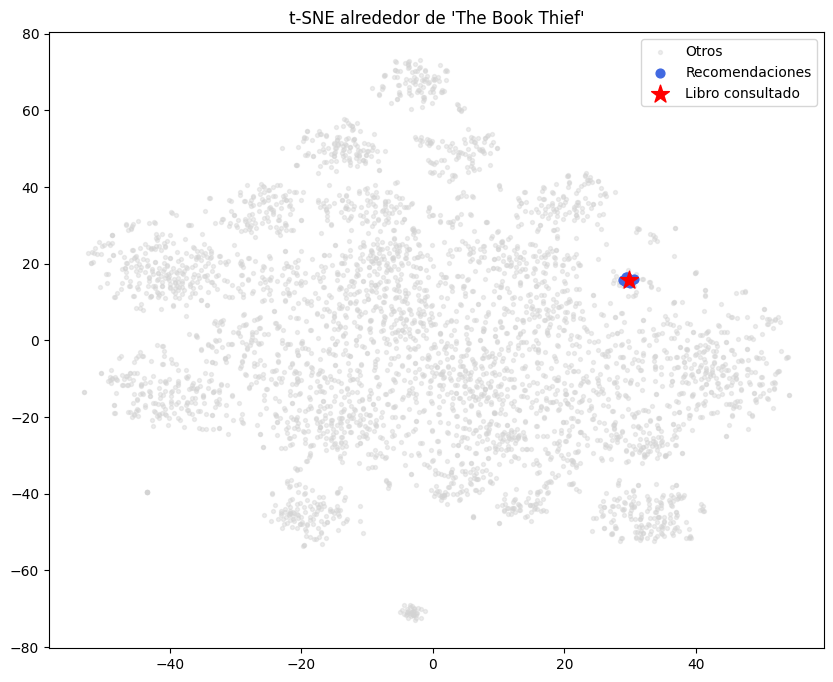

In [226]:
#hay tantos datos que no se puede visualizar correctamente en un grafico
#para tratar con esto, tomo 4000 muestras aleatorias, y para asegurarme que este mi libro y sus recomendaciones, los agrego a mano
muestra = np.random.choice(len(X_scaled), size=4000, replace=False)
muestra = np.unique(np.concatenate([muestra, indices_recomendados, [indice_consultado]]))

plot_vecinos_knn(muestra, X_scaled, indice_consultado, indices_recomendados, df_recomendador)

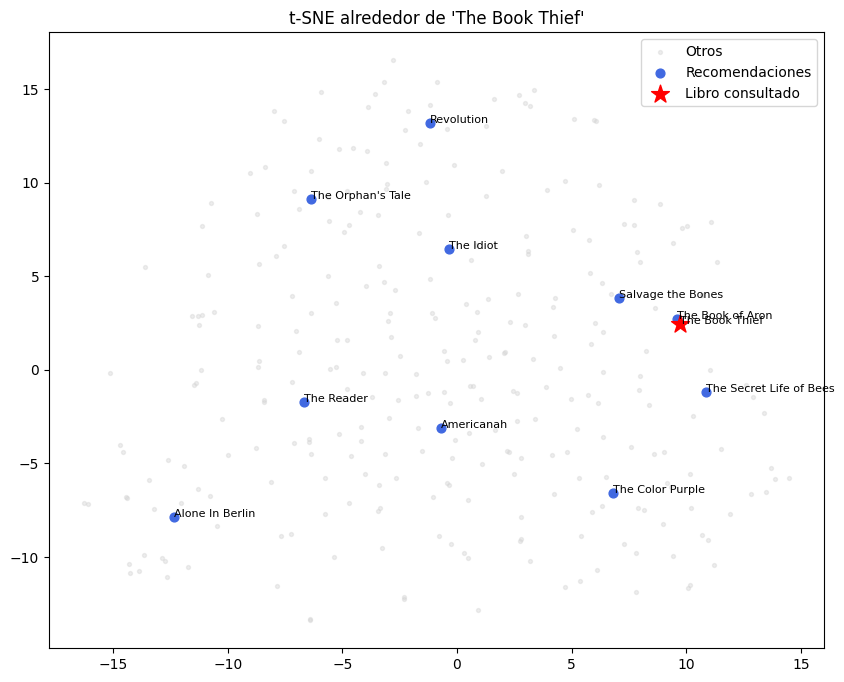

In [ ]:
#mismo grafico pero con zoom y etiquetas en los nombres
#para este grafico no quiero 4000 muestras, sino solo el libro consultado, sus vecinos, y los vecinos de los vecinos
muestra = {indice_consultado}
muestra.update(indices_recomendados)

#agregar vecinos de las recomendaciones
for i in indices_recomendados:
    _, nuevos_indices = modelo.kneighbors(X_scaled[i].reshape(1, -1), n_neighbors=50)
    muestra.update(nuevos_indices[0])
muestra = np.array(sorted(muestra))

plot_vecinos_knn(muestra, X_scaled, indice_consultado, indices_recomendados, df_recomendador, etiquetas = True)

In [ ]:
# def recomendar_por_libro(modelo, libros_df, X, titulo_autor, titulo_a_indice = titulo_a_indice, cant_recomendaciones = 5):
#     #Observaciones: la interfaz ya obliga al usuario a elegir un unico libro (al especificar tambien el autor),
#     #entonces ya no hace chequear el caso en el que len(resultados) > 1

#     #Ahora hay que ver que hacemos con cada posible situacion:
#     #Primer caso: No encontramos ningun libro con esos datos
#     if (titulo_autor not in titulo_a_indice):
#         print("No se encontro ningun libro con esos datos.")
#         return None
    
#     #Segundo caso: se encontro el libro
#     indice_libro = titulo_a_indice[titulo_autor]
#     #Obtengo las recomendaciones:
#     libros_recomendados, distancias = recomendar(modelo, X, indice_libro, cant_recomendaciones)
#     recomendaciones = libros_df.iloc[libros_recomendados].copy()
#     recomendaciones["distancia"] = distancias
#     columnas = ["title", "author_name", "publication_year"]
#     return recomendaciones[columnas]

## Motor de busqueda

Para una mejor experiencia con el usuario, implementamos con la ayuda de ChatGPT una barra de busqueda, y mas adelante una pequenia interfaz grafica.

In [14]:
all_titles = sorted(df["titulo_autor"].dropna().unique().tolist())

book_selector = widgets.Combobox(
    placeholder="Escribí un libro...",
    options=[],
    description="Libro:",
    ensure_option=False
)

def actualizar_opciones(change):
    texto = change["new"] or ""
    if len(texto) < 2:
        book_selector.options = []
        return
    matches = [t for t in all_titles if texto.lower() in t.lower()][:10]
    book_selector.options = matches

book_selector.observe(actualizar_opciones, names="value")

boton_recomendar = widgets.Button(
    description="Recomendar",
    button_style="success",
    icon="search"
)

salida = widgets.Output()

def al_hacer_click(boton):
    with salida:
        salida.clear_output()
        titulo_autor = book_selector.value
        recomendaciones = recomendar_por_libro(
            modelo,
            df,
            X_scaled,
            titulo_autor,
            titulo_a_indice
        )
        if recomendaciones is not None:
            display(recomendaciones)

boton_recomendar.on_click(al_hacer_click)

display(book_selector)
display(boton_recomendar)
display(salida)

Combobox(value='', description='Libro:', placeholder='Escribí un libro...')

Button(button_style='success', description='Recomendar', icon='search', style=ButtonStyle())

Output()

In [15]:
all_titles = sorted(df["titulo_autor"].dropna().unique().tolist())

search_text = widgets.Text(
    placeholder="Escribí un libro...",
    description="Buscar:"
)

match_selector = widgets.Select(
    options=[],
    rows=10,
    layout=widgets.Layout(height="220px", width="600px")
)

boton_recomendar = widgets.Button(
    description="Recomendar",
    button_style="success",
    icon="search"
)

salida = widgets.Output()

def actualizar_opciones(change):
    texto = (change["new"] or "").strip().lower()
    if texto == "":
        match_selector.options = []
        return
    matches = [t for t in all_titles if texto in t.lower()][:50]
    match_selector.options = matches

def al_hacer_click(boton):
    with salida:
        salida.clear_output()
        titulo_autor = match_selector.value
        recomendaciones = recomendar_por_libro(
            modelo,
            df,
            X_scaled,
            titulo_autor,
            titulo_a_indice
        )
        if recomendaciones is not None:
            display(recomendaciones)

search_text.observe(actualizar_opciones, names="value")
boton_recomendar.on_click(al_hacer_click)

display(search_text)
display(match_selector)
display(boton_recomendar)
display(salida)

Text(value='', description='Buscar:', placeholder='Escribí un libro...')

Select(layout=Layout(height='220px', width='600px'), options=(), rows=10, value=None)

Button(button_style='success', description='Recomendar', icon='search', style=ButtonStyle())

Output()

## Interfaz grafica

In [17]:
from IPython.display import HTML, display

def mostrar_recomendaciones(recomendaciones):

    html = """
    <h2 style="
        color:#2E86C1;
        font-family:Arial;
        margin-bottom:20px;
    ">
        📚 Libros recomendados
    </h2>

    <div style="
        display:flex;
        flex-wrap:wrap;
        gap:20px;
        justify-content:flex-start;
        align-items:flex-start;
    ">
    """

    for _, libro in recomendaciones.iterrows():

        html += f"""
        <div style="
            width:270px;
            min-height:280px;
            background:#F8F9FA;
            border:1px solid #D6DBDF;
            border-radius:15px;
            padding:18px;
            box-shadow:3px 3px 12px rgba(0,0,0,0.12);
            display:flex;
            flex-direction:column;
            justify-content:space-between;
            transition:0.2s;
        ">

            <div>

                <h3 style="
                    margin-top:0;
                    height:60px;
                    overflow:hidden;
                    color:#2C3E50;
                    font-family:Arial;
                ">
                    📖 {libro["title"]}
                </h3>

                <hr style="border:0;border-top:1px solid #E5E7E9;">

                <p style="
                    font-size:15px;
                    line-height:1.6;
                    color:#34495E;
                    font-family:Arial;
                ">

                👤 <b>Autor</b><br>
                {libro["author_name"]}<br><br>

                📅 <b>Año</b><br>
                {int(libro["publication_year"])}

                </p>

            </div>

            <div>

                <span style="
                    background:#FFF3CD;
                    color:#856404;
                    padding:6px 10px;
                    border-radius:8px;
                    font-weight:bold;
                    font-size:14px;
                ">
                    ⭐ {libro["average_rating"]:.2f}
                </span>

                <span style="
                    background:#D4EDDA;
                    color:#155724;
                    padding:6px 10px;
                    border-radius:8px;
                    font-weight:bold;
                    font-size:14px;
                    margin-left:8px;
                ">
                    🎯 {libro["similitud"]:.1f}%
                </span>

            </div>

        </div>
        """

    html += "</div>"

    display(HTML(html))

In [19]:
all_titles = sorted(df["titulo_autor"].dropna().unique().tolist())

book_selector = widgets.Combobox(
    placeholder="Escribí un libro...",
    options=[],
    description="Libro:",
    ensure_option=False,
    layout=widgets.Layout(width="700px")
)

def actualizar_opciones(change):
    texto = change["new"] or ""
    if len(texto) < 2:
        book_selector.options = []
        return
    matches = [t for t in all_titles if texto.lower() in t.lower()][:10]
    book_selector.options = matches

book_selector.observe(actualizar_opciones, names="value")

boton_recomendar = widgets.Button(
    description="Recomendar",
    button_style="success",
    icon="search",
    layout=widgets.Layout(width="220px", height="45px")
)

salida = widgets.Output()

def al_hacer_click(boton):
    with salida:
        salida.clear_output()
        titulo_autor = book_selector.value
        recomendaciones = recomendar_por_libro(
            modelo,
            df,
            X_scaled,
            titulo_autor,
            titulo_a_indice
        )
        if recomendaciones is not None:
            mostrar_recomendaciones(recomendaciones)

boton_recomendar.on_click(al_hacer_click)

titulo = widgets.HTML(
"""
<h1 style="color:#2E86C1;">
📚 Recomendador de Libros
</h1>

<p>
Escribí el nombre de un libro y elegilo de la lista.
</p>
"""
)

interfaz = widgets.VBox([
    titulo,
    book_selector,
    boton_recomendar,
    salida
])

display(interfaz)